# Investigação sociológica dos padrões encontrados

Este notebook aprofunda questões levantadas pela análise exploratória do Vigitel apresentada no **Notebook 01 — Análise Vigitel Curitiba**.

O objetivo é investigar os padrões encontrados a partir da combinação entre **análise quantitativa, evidências externas e interpretação sociológica**, considerando também explicações alternativas e limitações dos dados.

## Preparação dos dados

Nesta etapa são carregados os dados do Vigitel e selecionadas as variáveis necessárias às análises desenvolvidas neste notebook. As estimativas utilizam o peso amostral do Vigitel e consideram apenas os respondentes de Curitiba.

In [85]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [86]:
import os

arquivo_vigitel = '/content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/vigitel-2006-2024-peso-rake_slabel.csv'

print('Arquivo encontrado:', os.path.isfile(arquivo_vigitel))

Arquivo encontrado: True


In [87]:
import pandas as pd
import numpy as np

# Caminhos dos arquivos
arquivo_vigitel = '/content/drive/MyDrive/PUC/TCC/PORTFOLIO/PROJETO 1/vigitel-2006-2024-peso-rake_slabel.csv'
arquivo_dicionario = '/content/dicionario-vigitel-2006-2024.xlsx'

# Colunas necessárias nesta etapa
colunas = [
    'ano',
    'cidade',
    'pesorake2025',
    'feijao5'
]

# Leitura apenas das colunas necessárias
dados = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=colunas
)

# Seleção de Curitiba
curitiba = dados[dados['cidade'] == 7].copy()

print('Dimensão da base de Curitiba:', curitiba.shape)
print('Anos disponíveis:', sorted(curitiba['ano'].unique()))

Dimensão da base de Curitiba: (31196, 4)
Anos disponíveis: [np.int64(2006), np.int64(2007), np.int64(2008), np.int64(2009), np.int64(2010), np.int64(2011), np.int64(2012), np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018), np.int64(2019), np.int64(2020), np.int64(2021), np.int64(2023), np.int64(2024)]


---

## 1. Mudanças e rupturas temporais

A análise temporal identificou períodos de mudança acentuada que exigem investigação adicional. Esta seção examina essas rupturas antes de atribuí-las diretamente a mudanças nas práticas alimentares.


### 1.1 A queda do consumo regular de feijão a partir de 2016

**Pergunta de investigação:** Como interpretar a queda do consumo regular de feijão observada em Curitiba a partir de 2016 no contexto das transformações econômicas e das práticas alimentares brasileiras?

#### 1.1.1 Evidência encontrada no Vigitel

In [88]:
# Prevalência ponderada do consumo regular de feijão por ano

def prevalencia_ponderada(grupo):
    validos = grupo['feijao5'].notna()

    return (
        (grupo.loc[validos, 'feijao5'] * grupo.loc[validos, 'pesorake2025']).sum()
        / grupo.loc[validos, 'pesorake2025'].sum()
        * 100
    )

feijao_ano = (
    curitiba
    .groupby('ano')
    .apply(prevalencia_ponderada, include_groups=False)
    .rename('Consumo regular de feijão (%)')
    .to_frame()
)

# Selecionar os anos próximos à ruptura
feijao_ruptura = feijao_ano.loc[[2014, 2015, 2016, 2017]].copy()

# Variação em pontos percentuais
feijao_ruptura['Variação anual (p.p.)'] = (
    feijao_ruptura['Consumo regular de feijão (%)'].diff()
)

display(feijao_ruptura.round(1))

/tmp/ipykernel_1336/734464033.py:7: RuntimeWarning: invalid value encountered in scalar divide
  (grupo.loc[validos, 'feijao5'] * grupo.loc[validos, 'pesorake2025']).sum()


,Consumo regular de feijão (%),Variação anual (p.p.)
ano,,
2014,61.1,NaN
2015,64.4,3.3
2016,47.8,-16.6
2017,47.0,-0.8


**Ruptura observada em 2016.** Entre 2014 e 2015, a prevalência de consumo regular de feijão em Curitiba aumentou de 61,1% para 64,4%. Em 2016, entretanto, caiu para 47,8%, uma redução de 16,6 pontos percentuais em apenas um ano. Em 2017, a prevalência permaneceu em patamar semelhante (47,0%).

A magnitude e a concentração temporal dessa mudança justificam investigar se a ruptura ocorreu de forma generalizada entre diferentes grupos da população e se pode estar relacionada a mudanças na composição da amostra, nas condições materiais de acesso ao alimento ou em outros fatores contextuais.

### 1.1.2 Transformações das práticas alimentares brasileiras

A análise do Vigitel permite identificar a queda do consumo regular de feijão em Curitiba, mas não explica, isoladamente, os processos sociais relacionados a essa mudança. Por isso, é importante situar o padrão observado a partir de outras fontes de dados e estudos sobre as transformações das práticas alimentares brasileiras.

Dados da Pesquisa de Orçamentos Familiares (POF) mostram que a redução do consumo de feijão antecede a ruptura observada em Curitiba em 2016. A frequência de consumo de feijão no Brasil caiu de 72,8% em 2008–2009 para 60,0% em 2017–2018. A aquisição domiciliar do alimento apresenta uma tendência ainda mais longa, passando de 12,4 kg per capita em 2002–2003 para 9,1 kg em 2008–2009 e 5,9 kg em 2017–2018. No mesmo período, alimentos in natura ou minimamente processados perderam participação nos domicílios, enquanto alimentos processados e ultraprocessados ganharam espaço.

Essa mudança ocorre em meio a transformações na organização cotidiana da alimentação. A redução do tempo dedicado ao preparo das refeições, mudanças na composição dos domicílios e a busca por praticidade favorecem alimentos prontos ou que exigem menor tempo de preparação. Assim, refeições tradicionalmente estruturadas em torno de arroz e feijão passam a dividir espaço com lanches, refeições prontas, congelados e produtos ultraprocessados. A redução do consumo de feijão pode ser compreendida, portanto, como parte de mudanças mais amplas nas rotinas e práticas alimentares brasileiras.

Essa perspectiva também ajuda a interpretar a queda registrada em Curitiba em 2016. O aumento expressivo do preço do feijão naquele ano pode ter contribuído para intensificar uma tendência que já estava em curso, mas não explica seu desenvolvimento no longo prazo. A ruptura observada pode, assim, refletir a combinação entre transformações de longo prazo das práticas alimentares e condições econômicas específicas daquele período, analisadas na próxima seção.

### 1.1.3 Condições materiais de acesso à alimentação

A redução do consumo de feijão não pode ser explicada apenas pelo preço. Como discutido anteriormente, essa tendência antecede 2016 e está relacionada a transformações mais amplas das práticas alimentares. Evidências de períodos em que o consumo continuou diminuindo apesar da queda dos preços reforçam que outros fatores também influenciam esse processo.

Em 2016, contudo, houve uma conjuntura particularmente desfavorável ao acesso ao feijão. No Paraná, a produção da safra 2015/16 foi 17% inferior à do ano anterior, enquanto o preço recebido pelos produtores pelo feijão de cor passou de R$110 para R$395 por saca entre julho de 2015 e julho de 2016, aumento de aproximadamente 260%. A menor oferta esteve associada à redução da área plantada e a problemas climáticos, incluindo o excesso de chuvas no Paraná.

O aumento do preço do feijão ocorreu em um período de piora das condições econômicas das famílias. Segundo a PNAD Contínua, a taxa média de desemprego no Brasil passou de 8,5% em 2015 para 11,5% em 2016, enquanto o rendimento médio real habitual caiu 2,3%. Na Região Sul, o desemprego passou de 5,5% no segundo trimestre de 2015 para 8,0% no mesmo período de 2016. Em outras palavras, mais pessoas estavam desempregadas e a renda média dos trabalhadores havia diminuído justamente quando o preço do feijão aumentou de forma expressiva.

Esse cenário pode ter dificultado o acesso ao alimento, especialmente entre famílias com menor disponibilidade de renda. Assim, o aumento do preço do feijão em 2016, combinado à redução do poder de compra, constitui uma explicação plausível para a intensidade da queda observada em Curitiba naquele ano. Isso não significa que esses fatores tenham iniciado a redução do consumo, que já vinha ocorrendo anteriormente, mas que podem ter acentuado uma tendência em curso. Como o Vigitel não permite relacionar diretamente a renda e o preço pago pelos alimentos ao consumo individual, essa interpretação deve ser tratada como uma hipótese contextual, e não como uma relação causal demonstrada.

Como o consumo regular de feijão é mais frequente entre pessoas com menor escolaridade, surge uma questão adicional: a queda observada entre 2015 e 2016 ocorreu de forma semelhante entre os diferentes grupos sociais? A próxima seção investiga essa questão utilizando a escolaridade como uma dimensão da diferenciação social.

Referências: IBGE, Conab, CEPEA-ESALQ
Evidência complementar: https://g1.globo.com/pr/parana/caminhos-do-campo/noticia/2016/03/excesso-de-chuva-compromete-safra-de-feijao-no-parana-e-dispara-preco

### 1.1.4 Escolaridade e diferenciação social do consumo

A análise anterior mostrou que o consumo regular de feijão em Curitiba caiu de forma expressiva entre 2015 e 2016. Para investigar se essa redução ocorreu de maneira semelhante entre diferentes grupos da população, comparamos a variação do indicador segundo nível de escolaridade.

A escolaridade é tratada aqui como uma dimensão da diferenciação social relacionada ao capital cultural, considerando que os padrões alimentares são socialmente estruturados e se relacionam às posições ocupadas pelos indivíduos no espaço social (Bertoncelo, 2019).

**Pergunta:** A queda do consumo regular de feijão entre 2015 e 2016 ocorreu de forma semelhante entre os diferentes níveis de escolaridade?

In [89]:
# Carregar o dicionário de variáveis do Vigitel

dicionario = pd.read_excel(
    arquivo_dicionario,
    sheet_name='Variáveis_Vigitel',
    header=2
)

# Localizar variáveis relacionadas à escolaridade
dicionario[
    dicionario['Variable label']
    .astype(str)
    .str.contains('escolar|estudo|instrução', case=False, na=False)
][['Variable name', 'Variable label']]

,Variable name,Variable label
43,q8_anos,anos de estudo
897,cat_esc,Categorias (idade | sexo) para imputação da e...
898,fesc,escolaridade
901,fxesc,faixa de escolaridade


In [90]:
# Carregar escolaridade para a análise de 2015 e 2016

dados_escolaridade = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=['ano', 'cidade', 'pesorake2025', 'feijao5', 'q8_anos']
)

# Selecionar Curitiba e os anos de interesse
esc = dados_escolaridade[
    (dados_escolaridade['cidade'] == 7) &
    (dados_escolaridade['ano'].isin([2015, 2016]))
].copy()

# Criar faixas de escolaridade
esc['Escolaridade'] = pd.cut(
    esc['q8_anos'],
    bins=[-1, 8, 11, np.inf],
    labels=['0–8 anos', '9–11 anos', '12+ anos']
)

# Calcular prevalência ponderada de consumo regular de feijão
resultados = []

for (ano, escolaridade), grupo in esc.groupby(
    ['ano', 'Escolaridade'],
    observed=True
):
    validos = grupo[['feijao5', 'pesorake2025']].dropna()

    prevalencia = np.average(
        validos['feijao5'],
        weights=validos['pesorake2025']
    ) * 100

    resultados.append([ano, escolaridade, prevalencia])

tabela_escolaridade = pd.DataFrame(
    resultados,
    columns=['Ano', 'Escolaridade', 'Consumo regular de feijão (%)']
)

tabela_escolaridade

,Ano,Escolaridade,Consumo regular de feijão (%)
0,2015,0–8 anos,74.607923
1,2015,9–11 anos,65.914785
2,2015,12+ anos,53.752641
3,2016,0–8 anos,57.897524
4,2016,9–11 anos,54.046811
5,2016,12+ anos,35.901001


In [91]:
# Comparar 2015 e 2016 por escolaridade

comparacao_escolaridade = (
    tabela_escolaridade
    .pivot(
        index='Escolaridade',
        columns='Ano',
        values='Consumo regular de feijão (%)'
    )
)

comparacao_escolaridade['Variação (p.p.)'] = (
    comparacao_escolaridade[2016] - comparacao_escolaridade[2015]
)

comparacao_escolaridade.columns.name = None
comparacao_escolaridade = comparacao_escolaridade.rename(
    columns={2015: '2015 (%)', 2016: '2016 (%)'}
)

display(comparacao_escolaridade.round(1))

,2015 (%),2016 (%),Variação (p.p.)
Escolaridade,,,
0–8 anos,74.6,57.9,-16.7
12+ anos,53.8,35.9,-17.9
9–11 anos,65.9,54.0,-11.9


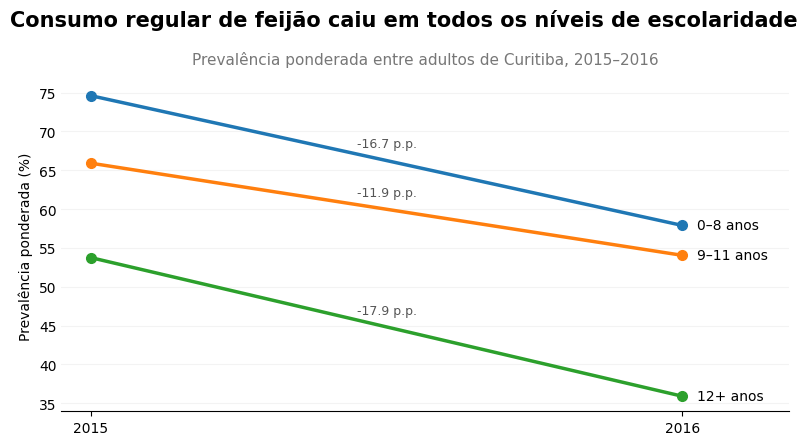

In [92]:
# Queda do consumo regular de feijão por escolaridade, 2015–2016

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

ordem = ['0–8 anos', '9–11 anos', '12+ anos']

for grupo in ordem:

    valores = comparacao_escolaridade.loc[grupo]

    valor_2015 = valores['2015 (%)']
    valor_2016 = valores['2016 (%)']
    queda = valor_2016 - valor_2015

    ax.plot(
        [2015, 2016],
        [valor_2015, valor_2016],
        marker='o',
        markersize=7,
        linewidth=2.5
    )

    # Identificação direta das linhas
    ax.text(
        2016.025,
        valor_2016,
        grupo,
        va='center',
        fontsize=10
    )

    # Variação em pontos percentuais
    # deslocada para cima da linha
    ax.text(
        2015.50,
        (valor_2015 + valor_2016) / 2 + 1.3,
        f'{queda:.1f} p.p.',
        fontsize=9,
        color='#555555',
        ha='center',
        va='bottom'
    )

# Eixo X
ax.set_xticks([2015, 2016])
ax.set_xlim(2014.95, 2016.18)

# Eixo Y
ax.set_ylabel(
    'Prevalência ponderada (%)',
    fontsize=10
)

ax.set_xlabel('')

# Título e subtítulo
fig.suptitle(
    'Consumo regular de feijão caiu em todos os níveis de escolaridade',
    fontsize=15,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2015–2016',
    fontsize=11,
    color='#777777',
    pad=12
)

# Limpeza visual
ax.grid(axis='y', alpha=0.15)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

In [93]:
# Definindo a variável 'tabela_pandemia' com as prevalências ponderadas para o período de 2018–2023

rotulos = {
    'frutareg': 'Frutas regulares',
    'flvreco': 'Frutas e hortaliças recomendadas',
    'refritl5': 'Refrigerantes regulares',
    'score_upp_2cat': '5+ grupos de ultraprocessados'
}

resultados_pandemia = []

for ano in [2018, 2019, 2020, 2021, 2023]:
    grupo_ano = curitiba_pandemia[curitiba_pandemia['ano'] == ano]

    for indicador in indicadores_pandemia:
        validos = grupo_ano[[indicador, 'pesorake2025']].dropna()

        if not validos.empty and validos['pesorake2025'].sum() > 0:
            prevalencia = np.average(
                validos[indicador],
                weights=validos['pesorake2025']
            ) * 100
        else:
            prevalencia = np.nan

        resultados_pandemia.append([
            ano,
            rotulos[indicador],
            prevalencia
        ])

tabela_pandemia = pd.DataFrame(
    resultados_pandemia,
    columns=['Ano', 'Indicador', 'Prevalência (%)']
)

tabela_pandemia = tabela_pandemia.pivot(
    index='Ano',
    columns='Indicador',
    values='Prevalência (%)'
)

display(tabela_pandemia.round(1))

Indicador,5+ grupos de ultraprocessados,Frutas e hortaliças recomendadas,Frutas regulares,Refrigerantes regulares
Ano,,,,
2018,21.1,26.3,60.3,17.4
2019,21.4,28.0,58.7,18.0
2020,23.0,25.1,59.9,20.4
2021,25.3,27.1,60.7,17.3
2023,22.4,26.8,57.3,21.5


In [94]:
print("Tipo do índice:", tabela_pandemia.index.dtype)
print("Anos:", tabela_pandemia.index.tolist())
print("Valores disponíveis por ano:")
print(tabela_pandemia.notna().sum(axis=1))

Tipo do índice: int64
Anos: [2018, 2019, 2020, 2021, 2023]
Valores disponíveis por ano:
Ano
2018    4
2019    4
2020    4
2021    4
2023    4
dtype: int64


A queda foi observada nos três níveis de escolaridade. A prevalência do consumo regular de feijão caiu 16,7 p.p. entre pessoas com 0–8 anos de estudo, 11,9 p.p. entre aquelas com 9–11 anos e 17,9 p.p. no grupo com 12 anos ou mais. Apesar da redução generalizada, permaneceu uma diferença importante: o consumo regular de feijão era mais frequente entre pessoas com menor escolaridade nos dois anos analisados.

Esse resultado dialoga com análises da POF 2008–2009, nas quais padrões caracterizados pelo consumo frequente de arroz e feijão aparecem associados a grupos com menores dotações de capital econômico e cultural (Bertoncelo, 2019). Os resultados de Curitiba também apontam para uma diferenciação social das práticas alimentares, mas não permitem atribuir a queda de 2016 à escolaridade ou à classe social: a redução ocorreu nos três grupos, sobre um padrão de consumo que já apresentava diferenças segundo escolaridade.

#### 1.1.5 Síntese das evidências

A queda do consumo regular de feijão em Curitiba entre 2015 e 2016 ocorreu sobre uma tendência de redução que já estava em curso no Brasil. Outras fontes mostram que o consumo de feijão vinha diminuindo em meio a transformações nas práticas alimentares, como mudanças nas rotinas de preparo das refeições e o crescimento do consumo de alimentos prontos e ultraprocessados.

Em 2016, essa tendência coincidiu com uma conjuntura particularmente desfavorável: houve redução da produção e forte aumento do preço do feijão, ao mesmo tempo em que cresceram o desemprego e a perda de poder de compra. Esses fatores podem ter contribuído para acentuar a queda observada naquele ano em Curitiba.

A análise por escolaridade acrescenta uma dimensão social ao fenômeno. Embora a redução tenha ocorrido nos três grupos analisados, o consumo regular de feijão permaneceu mais frequente entre pessoas com menor escolaridade, indicando diferenças sociais antes e depois da ruptura.

Em conjunto, as evidências sugerem que a queda de 2016 deve ser compreendida na interseção entre uma transformação de longo prazo das práticas alimentares, condições econômicas específicas daquele período e padrões socialmente diferenciados de consumo. Os dados disponíveis permitem contextualizar e formular explicações plausíveis para a ruptura, mas não determinar o peso de cada fator nem estabelecer relações causais.

## 1.2 Alimentação durante 2020–2021

A pandemia de COVID-19 impactou as rotinas de trabalho, circulação, organização doméstica e acesso à alimentação. Por esse motivo, esta seção investiga se os indicadores alimentares de Curitiba apresentaram mudanças atípicas durante 2020–2021 em relação às tendências observadas nos demais anos da série.

**Pergunta:** As mudanças observadas nos indicadores alimentares durante 2020–2021 diferem das tendências observadas nos demais anos?

### 1.2.1 Evidências encontradas no Vigitel

Para verificar se 2020–2021 apresentaram mudanças atípicas, foram selecionados quatro indicadores que representam diferentes dimensões das práticas alimentares: consumo regular de frutas, consumo recomendado de frutas e hortaliças, consumo regular de refrigerantes e consumo de cinco ou mais grupos de alimentos ultraprocessados.

A análise compara o comportamento desses indicadores durante 2020–2021 com os anos imediatamente anteriores e posteriores disponíveis na série.

In [95]:
# Indicadores selecionados para análise de 2020–2021

indicadores_pandemia = [
    'frutareg',
    'flvreco',
    'refritl5',
    'score_upp_2cat'
]

dados_pandemia = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=[
        'ano',
        'cidade',
        'pesorake2025',
        *indicadores_pandemia
    ]
)

curitiba_pandemia = dados_pandemia[
    dados_pandemia['cidade'] == 7
].copy()

curitiba_pandemia.shape

(31196, 7)

In [96]:
# Prevalências ponderadas dos indicadores selecionados

rotulos = {
    'frutareg': 'Frutas regulares',
    'flvreco': 'Frutas e hortaliças recomendadas',
    'refritl5': 'Refrigerantes regulares',
    'score_upp_2cat': '5+ grupos de ultraprocessados'
}

resultados = []

for ano in [2018, 2019, 2020, 2021, 2023]:
    grupo_ano = curitiba_pandemia[curitiba_pandemia['ano'] == ano]

    for indicador in indicadores_pandemia:
        validos = grupo_ano[[indicador, 'pesorake2025']].dropna()

        # Verifica se há dados válidos e se a soma dos pesos é maior que zero
        if not validos.empty and validos['pesorake2025'].sum() > 0:
            prevalencia = np.average(
                validos[indicador],
                weights=validos['pesorake2025']
            ) * 100
        else:
            prevalencia = np.nan

        resultados.append([
            ano,
            rotulos[indicador],
            prevalencia
        ])

tabela_pandemia = pd.DataFrame(
    resultados,
    columns=['Ano', 'Indicador', 'Prevalência (%)']
)

tabela_pandemia = tabela_pandemia.pivot(
    index='Ano',
    columns='Indicador',
    values='Prevalência (%)'
)

display(tabela_pandemia.round(1))

Indicador,5+ grupos de ultraprocessados,Frutas e hortaliças recomendadas,Frutas regulares,Refrigerantes regulares
Ano,,,,
2018,21.1,26.3,60.3,17.4
2019,21.4,28.0,58.7,18.0
2020,23.0,25.1,59.9,20.4
2021,25.3,27.1,60.7,17.3
2023,22.4,26.8,57.3,21.5


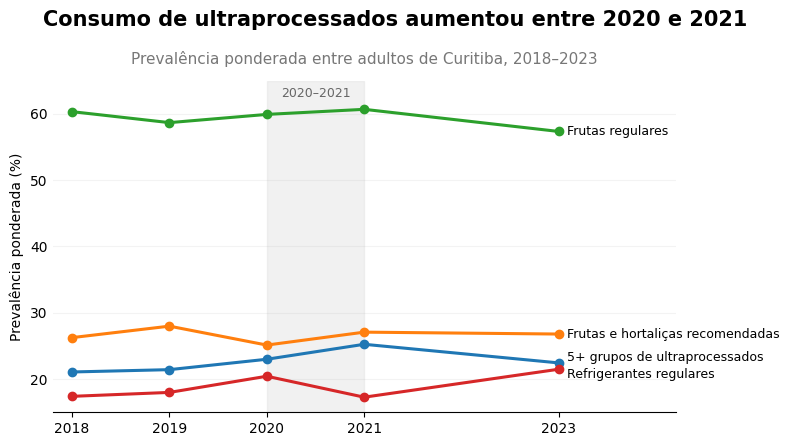

In [97]:
# Evolução dos indicadores alimentares no período de 2018–2023

import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(8, 4.5))

# Plotar as séries
for coluna in tabela_pandemia.columns:
    ax.plot(
        tabela_pandemia.index,
        tabela_pandemia[coluna],
        marker='o',
        markersize=6,
        linewidth=2.2
    )

# Destacar 2020–2021
ax.axvspan(
    2020,
    2021,
    color='#D9D9D9',
    alpha=0.35,
    zorder=0
)

# Eixos
ax.set_xlabel('')
ax.set_ylabel(
    'Prevalência ponderada (%)',
    fontsize=10
)

ax.set_xticks([2018, 2019, 2020, 2021, 2023])
ax.set_xlim(2017.8, 2024.2)
ax.set_ylim(15, 65)

# Identificação do período
ax.text(
    2020.5,
    63,
    '2020–2021',
    ha='center',
    va='center',
    fontsize=9,
    color='#666666'
)

# Ajustes individuais dos rótulos à direita
ajustes_rotulos = {
    '5+ grupos de ultraprocessados': 0.8,
    'Refrigerantes regulares': -0.8
}

# Identificação direta das linhas
for coluna in tabela_pandemia.columns:

    serie = tabela_pandemia[coluna].dropna()

    deslocamento = ajustes_rotulos.get(coluna, 0)

    ax.text(
        serie.index[-1] + 0.08,
        serie.iloc[-1] + deslocamento,
        coluna,
        va='center',
        fontsize=9
    )

# Título e subtítulo
fig.suptitle(
    'Consumo de ultraprocessados aumentou entre 2020 e 2021',
    fontsize=15,
    fontweight='bold',
    y=0.98
)

ax.set_title(
    'Prevalência ponderada entre adultos de Curitiba, 2018–2023',
    fontsize=11,
    color='#777777',
    pad=12
)

# Limpeza visual
ax.grid(axis='y', alpha=0.15)

ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.spines['left'].set_visible(False)

ax.tick_params(axis='y', length=0)

plt.tight_layout()
plt.show()

Entre os indicadores analisados, o comportamento mais distinto durante 2020–2021 ocorreu no consumo de cinco ou mais grupos de alimentos ultraprocessados. A prevalência aumentou de 21,4% em 2019 para 23,0% em 2020 e 25,3% em 2021, recuando para 22,4% em 2023.

Os demais indicadores apresentaram oscilações no período, mas sem uma mudança tão claramente concentrada nos anos de 2020–2021. Assim, os dados sugerem uma alteração temporária particularmente relevante no indicador de ultraprocessados.

Esse padrão temporal, entretanto, não permite atribuir a mudança diretamente à pandemia. Além de possíveis alterações nas práticas alimentares, devem ser consideradas mudanças nas condições sociais do período e aspectos metodológicos da coleta do Vigitel.

### 1.2.2 Mudanças metodológicas na coleta de dados durante a pandemia

O aumento do consumo de cinco ou mais grupos de alimentos ultraprocessados em 2020–2021 ocorreu durante um período de mudanças excepcionais na organização da vida cotidiana. A pandemia alterou rotinas de trabalho, permanência no domicílio, mobilidade e formas de aquisição e preparação dos alimentos, oferecendo um contexto plausível para mudanças nas práticas alimentares.

Entretanto, a comparação exige cautela. Em 2020 e 2021, dificuldades de coleta relacionadas à pandemia levaram o Vigitel a trabalhar com amostras menores: em Curitiba, foram realizadas 1.004 entrevistas em 2020 e 1.008 em 2021, frente a 2.058 em 2019. Além disso, o Ministério da Saúde informa que, em 2020, as entrevistas ficaram concentradas nos primeiros meses do ano, diferentemente da distribuição da coleta ao longo do ano adotada anteriormente, o que pode introduzir efeitos sazonais nas estimativas.

Assim, o crescimento observado no indicador de ultraprocessados é compatível com uma mudança nas práticas alimentares durante o período da pandemia, mas os dados não permitem atribuí-lo diretamente a ela. Parte da variação também pode estar relacionada às particularidades metodológicas da coleta realizada no período.

Referências: Vigitel 2020, Vigitel 2021

### 1.2.3 Síntese das evidências


A maioria dos indicadores alimentares analisados não apresentou mudanças expressivas em Curitiba durante 2020–2021. A principal alteração ocorreu no consumo de cinco ou mais grupos de alimentos ultraprocessados, cuja prevalência passou de 21,4% em 2019 para 23,0% em 2020 e 25,3% em 2021, recuando para 22,4% em 2023. Os demais indicadores apresentaram variações menores no período.

Embora esse aumento coincida com a pandemia de COVID-19 e com as mudanças nas rotinas cotidianas provocadas por ela, os resultados devem ser interpretados com cautela. Em 2020 e 2021, o Vigitel apresentou amostras menores em Curitiba e, em 2020, houve alteração na distribuição temporal das entrevistas, fatores que podem ter influenciado as estimativas.

Assim, os dados mostram um aumento específico no consumo de ultraprocessados durante 2020–2021, mas não permitem determinar se essa mudança esteve relacionada às alterações nas práticas alimentares durante a pandemia ou às particularidades metodológicas da coleta de dados. A pandemia constitui, portanto, um contexto relevante para interpretar o resultado, mas não uma causa demonstrada por esta análise.

## 2. Interseção entre características sociodemográficas

As análises anteriores mostraram que os indicadores alimentares variam segundo características como sexo, idade e escolaridade. Entretanto, essas características não atuam de forma isolada e estão simultaneamente presentes na composição dos diferentes grupos da população.

Esta etapa investiga se as diferenças observadas permanecem quando sexo, idade e escolaridade são considerados conjuntamente.

**Pergunta:** As diferenças alimentares associadas a sexo, idade e escolaridade permanecem quando essas características são analisadas simultaneamente?


### 2.1 Análise conjunta das características sociodemográficas

Para analisar conjuntamente as relações entre características sociodemográficas e alimentação, foram utilizados modelos de regressão logística para dois indicadores: consumo regular de frutas e consumo regular de refrigerantes.

Os modelos consideram sexo, faixa etária, escolaridade e ano simultaneamente. Isso permite analisar a relação de cada característica com o comportamento alimentar enquanto as demais são mantidas constantes. Por exemplo, ao analisar a relação entre sexo e consumo de frutas, o modelo considera as diferenças de idade, escolaridade e ano entre os participantes.


In [98]:
# Preparação da base para análise multivariada

colunas_modelo = [
    'ano',
    'cidade',
    'pesorake2025',
    'q6',        # idade
    'q7',        # sexo
    'q8_anos',   # escolaridade
    'frutareg',
    'refritl5'
]

dados_modelo = pd.read_csv(
    arquivo_vigitel,
    encoding='latin1',
    usecols=colunas_modelo
)

modelo = dados_modelo[
    dados_modelo['cidade'] == 7
].copy()

print('Dimensão da base:', modelo.shape)

# Criação das categorias sociodemográficas

modelo['Sexo'] = modelo['q7'].map({
    1: 'Masculino',
    2: 'Feminino'
})

modelo['Faixa etária'] = pd.cut(
    modelo['q6'],
    bins=[17, 24, 34, 44, 54, 64, np.inf],
    labels=['18–24', '25–34', '35–44', '45–54', '55–64', '65+']
)

modelo['Escolaridade'] = pd.cut(
    modelo['q8_anos'],
    bins=[-1, 8, 11, np.inf],
    labels=['0–8 anos', '9–11 anos', '12+ anos']
)

modelo[
    ['Sexo', 'Faixa etária', 'Escolaridade']
].head()

Dimensão da base: (31196, 8)


,Sexo,Faixa etária,Escolaridade
0,Feminino,35–44,0–8 anos
4,Feminino,25–34,12+ anos
23,Feminino,35–44,9–11 anos
31,Feminino,45–54,0–8 anos
34,Masculino,65+,9–11 anos


#### Consumo regular de frutas

In [99]:
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Regressão logística — consumo regular de frutas

reg_frutas = smf.glm(
    formula=(
        'frutareg ~ C(Sexo) + C(Q("Faixa etária")) + '
        'C(Escolaridade) + ano'
    ),
    data=modelo,
    family=sm.families.Binomial()
).fit()

print(reg_frutas.summary())

                 Generalized Linear Model Regression Results                  
Dep. Variable:               frutareg   No. Observations:                31196
Model:                            GLM   Df Residuals:                    31186
Model Family:                Binomial   Df Model:                            9
Link Function:                  Logit   Scale:                          1.0000
Method:                          IRLS   Log-Likelihood:                -18925.
Date:                Tue, 13 Oct 2026   Deviance:                       37849.
Time:                        18:20:03   Pearson chi2:                 3.11e+04
No. Iterations:                     4   Pseudo R-squ. (CS):            0.08755
Covariance Type:            nonrobust                                         
                                    coef    std err          z      P>|z|      [0.025      0.975]
-------------------------------------------------------------------------------------------------
Intercept     

In [100]:
# Odds ratios e intervalos de confiança

or_frutas = pd.DataFrame({
    'OR': np.exp(reg_frutas.params),
    'IC 2,5%': np.exp(reg_frutas.conf_int()[0]),
    'IC 97,5%': np.exp(reg_frutas.conf_int()[1]),
    'p-valor': reg_frutas.pvalues
})

or_frutas = or_frutas.drop(['Intercept', 'ano'])

display(or_frutas.round(3))

,OR,"IC 2,5%","IC 97,5%",p-valor
C(Sexo)[T.Masculino],0.527,0.502,0.554,0.000
"C(Q(""Faixa etária""))[T.25–34]",0.997,0.902,1.103,0.959
"C(Q(""Faixa etária""))[T.35–44]",1.315,1.193,1.449,0.000
"C(Q(""Faixa etária""))[T.45–54]",1.959,1.775,2.161,0.000
"C(Q(""Faixa etária""))[T.55–64]",2.886,2.606,3.196,0.000
"C(Q(""Faixa etária""))[T.65+]",4.666,4.211,5.169,0.000
C(Escolaridade)[T.9–11 anos],1.378,1.294,1.468,0.000
C(Escolaridade)[T.12+ anos],1.858,1.741,1.982,0.000


O modelo permite analisar separadamente a relação entre sexo, idade e escolaridade e o consumo regular de frutas, mantendo constantes as demais características.

Primeiro, foi identificada uma diferença segundo sexo: homens apresentaram menor chance de consumo regular de frutas do que mulheres (OR = 0,53).

Segundo, foi identificado um gradiente etário. Em comparação às pessoas de 18–24 anos, as chances de consumo regular de frutas aumentaram progressivamente nas faixas etárias mais elevadas. Entre pessoas com 65 anos ou mais, a chance foi 4,67 vezes maior. A única exceção foi a faixa de 25–34 anos, que não apresentou diferença estatisticamente significativa em relação ao grupo de referência.

Terceiro, também foi identificado um gradiente segundo escolaridade. Em comparação às pessoas com 0–8 anos de estudo, aquelas com 9–11 anos apresentaram chance 1,38 vez maior de consumo regular de frutas, enquanto entre pessoas com 12 anos ou mais a chance foi 1,86 vez maior.

Assim, mesmo quando sexo, idade, escolaridade e ano são considerados simultaneamente, permanecem diferenças sociodemográficas importantes no consumo regular de frutas.

#### Consumo regular de refrigerantes

In [101]:
# Regressão logística — consumo regular de refrigerantes

modelo_refri = modelo[
    ['refritl5', 'Sexo', 'Faixa etária',
     'Escolaridade', 'ano']
].dropna().copy()

reg_refri = smf.glm(
    formula=(
        'refritl5 ~ C(Sexo) + C(Q("Faixa etária")) + '
        'C(Escolaridade) + ano'
    ),
    data=modelo_refri,
    family=sm.families.Binomial()
).fit()

# Odds ratios e intervalos de confiança
or_refri = pd.DataFrame({
    'OR': np.exp(reg_refri.params),
    'IC 2,5%': np.exp(reg_refri.conf_int()[0]),
    'IC 97,5%': np.exp(reg_refri.conf_int()[1]),
    'p-valor': reg_refri.pvalues
})

or_refri = or_refri.drop(['Intercept', 'ano'])

display(or_refri.round(3))

,OR,"IC 2,5%","IC 97,5%",p-valor
C(Sexo)[T.Masculino],1.456,1.374,1.544,0.000
"C(Q(""Faixa etária""))[T.25–34]",0.940,0.841,1.050,0.270
"C(Q(""Faixa etária""))[T.35–44]",0.673,0.604,0.750,0.000
"C(Q(""Faixa etária""))[T.45–54]",0.502,0.450,0.561,0.000
"C(Q(""Faixa etária""))[T.55–64]",0.367,0.326,0.413,0.000
"C(Q(""Faixa etária""))[T.65+]",0.273,0.243,0.306,0.000
C(Escolaridade)[T.9–11 anos],0.987,0.916,1.063,0.724
C(Escolaridade)[T.12+ anos],0.744,0.688,0.803,0.000


O modelo permite analisar separadamente a relação entre sexo, idade e escolaridade e o consumo regular de refrigerantes, mantendo constantes as demais características.

Primeiro, foi identificada uma diferença segundo sexo: homens apresentaram maior chance de consumo regular de refrigerantes do que mulheres (OR = 1,46).

Segundo, foi identificado um gradiente etário. Em comparação às pessoas de 18–24 anos, as chances de consumo regular de refrigerantes diminuíram progressivamente nas faixas etárias mais elevadas, chegando a OR = 0,27 entre pessoas com 65 anos ou mais. A faixa de 25–34 anos não apresentou diferença estatisticamente significativa em relação ao grupo de referência.

Terceiro, foram observadas diferenças segundo escolaridade. Pessoas com 9–11 anos de estudo não apresentaram diferença estatisticamente significativa em relação ao grupo com 0–8 anos. Já entre aquelas com 12 anos ou mais de estudo, a chance de consumo regular de refrigerantes foi menor (OR = 0,74).

Assim, mesmo quando sexo, idade, escolaridade e ano são considerados simultaneamente, permanecem diferenças sociodemográficas importantes no consumo regular de refrigerantes.

### 2.2 Síntese das evidências


A análise conjunta de sexo, idade e escolaridade mostrou que essas características permanecem relacionadas aos comportamentos alimentares mesmo quando consideradas simultaneamente.

No consumo regular de frutas, homens apresentaram menor chance de consumo do que mulheres. Também foi identificado um gradiente de idade e escolaridade: o consumo foi mais frequente entre pessoas de maior idade e com maior escolaridade.

Para o consumo regular de refrigerantes, o padrão foi diferente. Homens apresentaram maior chance de consumo do que mulheres, enquanto as chances diminuíram progressivamente nas faixas etárias mais elevadas. Em relação à escolaridade, apenas o grupo com 12 anos ou mais de estudo apresentou menor chance de consumo em comparação ao grupo com 0–8 anos.

Os resultados mostram, portanto, que os hábitos alimentares analisados variam segundo diferentes características sociodemográficas. Além disso, frutas e refrigerantes apresentam padrões contrastantes, reforçando que as diferenças sociais na alimentação não ocorrem da mesma forma para todos os alimentos e comportamentos.

## 3. Interpretação sociológica dos resultados

Esta seção articula os resultados anteriores com pesquisas e literatura sobre alimentação no Brasil, considerando transformações do sistema alimentar, desigualdades sociais, gênero, geração, organização das refeições e mudanças nas práticas alimentares.


### 3.1 Classe, escolaridade e diferenciação social das práticas alimentares

As análises mostraram diferenças nos hábitos alimentares segundo escolaridade. Essas diferenças devem ser interpretadas em relação às condições materiais e sociais que influenciam as possibilidades de consumo, e não apenas como resultado de preferências individuais. Assim, este projeto entende a escolaridade como uma forma de diferenciação social, e não como equivalente à classe social.

Logo de início, um resultado que chamou atenção foi o maior consumo regular de feijão entre pessoas com menor escolaridade. Esse padrão também aparece em dados nacionais, que mostram maior frequência de arroz e feijão entre grupos de menor renda. Uma possível explicação está nas próprias características desses alimentos: o feijão tem custo relativamente baixo, bom rendimento após o preparo e, combinado ao arroz, forma uma refeição nutritiva e capaz de proporcionar energia e saciedade. Bertoncelo (2019) ajuda a compreender esse padrão ao mostrar que as escolhas alimentares também são condicionadas pelos recursos disponíveis. Enquanto grupos com menos recursos tendem a valorizar alimentos acessíveis e capazes de sustentar, uma maior renda amplia as possibilidades de diversificação da alimentação.

Essa perspectiva também mostra por que escolaridade ou renda não podem ser organizadas em uma escala simples de alimentação “melhor” ou “pior”. No caso de Curitiba, grupos de menor escolaridade apresentaram maior consumo de feijão, enquanto outros indicadores seguiram direções diferentes. As práticas alimentares refletem, portanto, combinações entre recursos econômicos, condições de vida, experiências sociais e possibilidades de escolha.

### 3.2 Gênero, cuidado e práticas alimentares

Os resultados mostraram diferenças nos hábitos alimentares de homens e mulheres. Mesmo considerando idade, escolaridade e ano, homens apresentaram menor chance de consumir frutas regularmente (OR = 0,53) e maior chance de consumir refrigerantes regularmente (OR = 1,46) em comparação às mulheres.

Essas diferenças podem estar relacionadas à forma como homens e mulheres foram historicamente envolvidos com a alimentação. Abdala mostra que tarefas como comprar alimentos, cozinhar e organizar as refeições da família foram tradicionalmente atribuídas às mulheres. Essa maior participação pode contribuir para diferenças nos conhecimentos e hábitos alimentares. Portanto, os resultados não indicam diferenças naturais entre homens e mulheres, mas podem refletir experiências e responsabilidades construídas socialmente.

Essa interpretação, porém, não pode ser comprovada diretamente pelo Vigitel. A pesquisa informa o sexo dos participantes e seus hábitos alimentares, mas não fornece dados a respeito de quem compra os alimentos, quem cozinha ou quem é responsável pela alimentação da família. Por isso, a literatura sobre gênero e cuidado ajuda a formular uma possível explicação para os resultados, mas não permite afirmar que essas responsabilidades sejam a causa das diferenças observadas.



### 3.3 Idade, geração e socialização alimentar

A idade foi uma das características mais relacionadas aos hábitos alimentares analisados. No modelo multivariado, a chance de consumo regular de frutas aumentou progressivamente nas faixas etárias mais elevadas, chegando a OR = 4,67 entre pessoas com 65 anos ou mais, em comparação ao grupo de 18–24 anos. Para refrigerantes, ocorreu o padrão inverso: a chance diminuiu com a idade, chegando a OR = 0,27 entre pessoas com 65 anos ou mais.

Essas diferenças não significam que as pessoas passem a consumir mais frutas e menos refrigerantes simplesmente porque envelhecem. Elas podem estar relacionadas tanto a mudanças que ocorrem ao longo da vida, como alterações nas rotinas e maior preocupação com a saúde, quanto a diferenças entre gerações que desenvolveram seus hábitos alimentares em épocas distintas.

Essa diferença entre gerações é especialmente relevante diante das transformações do sistema alimentar brasileiro. Pessoas mais velhas cresceram em um contexto com menor presença de alimentos processados e ultraprocessados, enquanto gerações mais jovens foram socializadas em um ambiente alimentar diferente. Assim, os resultados podem refletir tanto mudanças relacionadas ao envelhecimento quanto hábitos construídos ao longo da vida. Como o Vigitel não acompanha as mesmas pessoas ao longo dos anos, não é possível separar esses dois efeitos.

## 4. Limitações e explicações alternativas

Os resultados devem ser interpretados considerando algumas limitações do Vigitel. As informações são autorreferidas e, portanto, representam comportamentos declarados pelos participantes. Além disso, embora as análises descritivas utilizem os pesos disponibilizados pela pesquisa, os modelos multivariados foram aplicados de forma exploratória e não incorporam integralmente o desenho amostral complexo do Vigitel.

A comparação ao longo do tempo também exige cautela. Nem todos os indicadores estão disponíveis em todos os anos e algumas variáveis tiveram mudanças em sua definição. Por isso, foram utilizados apenas períodos comparáveis para cada indicador. O consumo de cinco ou mais grupos de ultraprocessados em 2024, por exemplo, não foi incluído na série de 2018–2023 porque sua forma de cálculo foi modificada.

Por fim, as análises identificam diferenças entre grupos e mudanças ao longo do tempo, mas não permitem determinar suas causas. Características como sexo, idade e escolaridade não medem diretamente fatores como renda, divisão das tarefas domésticas ou experiências de socialização alimentar. Da mesma forma, a queda do consumo de feijão em 2016 e as mudanças observadas durante 2020–2021 ocorreram em contextos econômicos e sociais específicos, mas não podem ser atribuídas diretamente a esses acontecimentos. A literatura foi utilizada para contextualizar os resultados e apresentar possíveis explicações, e não para estabelecer relações de causa e efeito.

## 5. Síntese interpretativa

A análise do Vigitel mostra que os hábitos alimentares da população adulta de Curitiba mudaram ao longo do período analisado, mas de formas diferentes conforme o alimento e o grupo da população. O consumo regular de frutas apresentou tendência de crescimento, enquanto o consumo regular de refrigerantes diminuiu. Outros indicadores apresentaram maior estabilidade ou mudanças específicas, como a queda expressiva do consumo regular de feijão em 2016.

A investigação mostrou que essas mudanças precisam ser compreendidas dentro de seus contextos sociais e econômicos. A redução do consumo de feijão, por exemplo, faz parte de uma tendência de longo prazo, mas a queda de 2016 ocorreu em um período de forte aumento do preço do alimento, redução da produção, aumento do desemprego e perda de poder de compra. Durante 2020–2021, o principal destaque foi o aumento do consumo de cinco ou mais grupos de ultraprocessados. Embora esse período coincida com as mudanças provocadas pela pandemia, as características da coleta do Vigitel nesses anos também exigem cautela na interpretação.

Os resultados também mostraram diferenças importantes segundo sexo, idade e escolaridade. Homens apresentaram menor chance de consumir frutas regularmente e maior chance de consumir refrigerantes do que mulheres. O consumo de frutas aumentou com a idade, enquanto o de refrigerantes diminuiu. A escolaridade também esteve relacionada aos hábitos alimentares, incluindo o maior consumo regular de feijão entre pessoas com menor escolaridade.

Em conjunto, os resultados mostram que os hábitos alimentares variam ao longo do tempo e entre diferentes grupos da população. Fatores como condições econômicas, idade, escolaridade e sexo ajudam a compreender essas diferenças. A análise sociológica complementa os dados ao relacionar os padrões observados aos contextos sociais em que a alimentação ocorre, sem atribuir essas mudanças a uma única causa.